In [98]:
from sklearn.metrics import precision_score, recall_score, ConfusionMatrixDisplay
from sklearn.model_selection import RandomizedSearchCV
import warnings
warnings.simplefilter("ignore")


from collections import Counter
from collections import defaultdict

# Base
import math as m

# Base 2.0
import numpy as np
import pandas as pd

# Grafici
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# SciPy
from scipy import stats
from scipy.cluster.hierarchy import (
    dendrogram,
    fcluster,
    linkage,
)
from scipy.spatial.distance import pdist, squareform

# Scikit-learn
from sklearn.cluster import (
    AgglomerativeClustering,
    BisectingKMeans,
    cluster_optics_dbscan,
    DBSCAN,
    KMeans,
    OPTICS,
)
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    RidgeCV,
    Lasso,
    LassoCV,
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score,
    r2_score,
    RocCurveDisplay,
    silhouette_score,
    silhouette_samples,
)
from sklearn.model_selection import (
    cross_val_score,
    train_test_split,
    StratifiedKFold,
)
from sklearn.naive_bayes import (
    CategoricalNB,
    GaussianNB,
)
from sklearn.neighbors import (
    KNeighborsClassifier,
    NearestNeighbors,
    KNeighborsRegressor,
)
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
)
from sklearn.tree import (
    DecisionTreeClassifier,
    DecisionTreeRegressor,
    plot_tree,
)
from pyod.models.knn import KNN
from scipy.spatial.distance import pdist, squareform
from tqdm import tqdm

# Librerie
import pandas as pd
import numpy as np

# High Dimensionality
from pyod.models.abod import ABOD

# Ensemble
from pyod.models.feature_bagging import FeatureBagging
# carico LOF per FeaBag, chiaramente si può cambiare a seconda del modello semplice scelto
from pyod.models.lof import LOF
from pyod.models.loda import LODA

# Foreste
from sklearn.ensemble import IsolationForest
from isotree import IsolationForest as EIF

from sklearn.manifold import TSNE


In [99]:
df_pulito= pd.read_parquet('df_pulito.parquet')
df_unlearn=df_pulito.drop(['risultati'], axis=1).copy()

standard_scaler = StandardScaler().set_output(transform="pandas")

y_da_binarizzare= np.array(df_unlearn['sii'])
y_pulito = np.where(y_da_binarizzare >= 2.0, 1, 0)
pciat_cols = [f"PCIAT-PCIAT_{i:02d}" for i in range(1, 21)]
X_pulito = df_unlearn.drop(columns=['id','sii','PCIAT-PCIAT_Total']+pciat_cols).copy() #

X_pulito_s = pd.DataFrame(
    standard_scaler.fit_transform(X_pulito), 
    columns=X_pulito.columns, 
    index=X_pulito.index
)

X_trainp, X_testp, y_trainp, y_testp = train_test_split(X_pulito, y_pulito, test_size=0.3, random_state=100, stratify=y_pulito)

#dati standardizzati, servivano solo per tomek
X_trainp_s, X_testp_s, y_trainp_s, y_testp_s = train_test_split(X_pulito_s, y_pulito, test_size=0.3, random_state=100, stratify=y_pulito)

In [100]:
print(pd.Series(y_testp).value_counts())
print(pd.Series(y_trainp).value_counts())
print(pd.Series(y_pulito).value_counts())

percentuali = pd.Series(y_pulito).value_counts(normalize=True) * 100
print(percentuali)
X_trainp.columns
# iperparametri decisiontree

0    2169
1     300
Name: count, dtype: int64
0    5060
1     700
Name: count, dtype: int64
0    7229
1    1000
Name: count, dtype: int64
0    87.847855
1    12.152145
Name: proportion, dtype: float64


Index(['Basic_Demos-Enroll_Season', 'Basic_Demos-Age', 'Basic_Demos-Sex',
       'CGAS-Season', 'CGAS-CGAS_Score', 'Physical-Season', 'Physical-Height',
       'Physical-Weight', 'Physical-Waist_Circumference',
       'Physical-Diastolic_BP', 'Physical-HeartRate', 'Physical-Systolic_BP',
       'Fitness_Endurance-Season', 'Fitness_Endurance-Max_Stage', 'FGC-Season',
       'FGC-FGC_CU', 'FGC-FGC_CU_Zone', 'FGC-FGC_GSND', 'FGC-FGC_GSND_Zone',
       'FGC-FGC_GSD', 'FGC-FGC_GSD_Zone', 'FGC-FGC_PU', 'FGC-FGC_PU_Zone',
       'FGC-FGC_SRL', 'FGC-FGC_SRL_Zone', 'FGC-FGC_SRR', 'FGC-FGC_SRR_Zone',
       'FGC-FGC_TL', 'FGC-FGC_TL_Zone', 'BIA-Season',
       'BIA-BIA_Activity_Level_num', 'BIA-BIA_BMC', 'BIA-BIA_BMR',
       'BIA-BIA_DEE', 'BIA-BIA_ECW', 'BIA-BIA_FFM', 'BIA-BIA_FFMI',
       'BIA-BIA_FMI', 'BIA-BIA_Fat', 'BIA-BIA_Frame_num', 'BIA-BIA_ICW',
       'BIA-BIA_LDM', 'BIA-BIA_LST', 'BIA-BIA_SMM', 'BIA-BIA_TBW',
       'PCIAT-Season', 'SDS-Season', 'PreInt_EduHx-Season',
       'PreIn

In [101]:
print('Avvio RandomizedSearchCV per DecisionTreeClassifier...')
param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 10, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4, 8]
}
clf = DecisionTreeClassifier(random_state=222)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=222)

random_search = RandomizedSearchCV(clf, param_distributions=param_dist, n_iter=20, scoring='f1', cv=5, random_state=222, n_jobs=-1)
random_search.fit(X_trainp, y_trainp)
best_clf = random_search.best_estimator_
print('Migliori iperparametri trovati:')
print(random_search.best_params_)
print(f'Miglior F1-score (Cross-Validation): {random_search.best_score_:.4f}')
clf = best_clf


Avvio RandomizedSearchCV per DecisionTreeClassifier...
Migliori iperparametri trovati:
{'min_samples_split': 10, 'min_samples_leaf': 2, 'max_depth': 20, 'criterion': 'gini'}
Miglior F1-score (Cross-Validation): 0.2131


In [102]:
best_base = best_clf
y_pred0 = best_base.predict(X_testp)
print('Accuracy %s' % accuracy_score(y_testp, y_pred0))
print('F1-score %s' % f1_score(y_testp, y_pred0, average=None))
print(classification_report(y_testp, y_pred0))
importances = pd.Series(best_base.feature_importances_, index=X_trainp.columns)
print(importances.sort_values(ascending=False).head(5))


Accuracy 0.8343458890238963
F1-score [0.9071931  0.22975518]
              precision    recall  f1-score   support

           0       0.89      0.92      0.91      2169
           1       0.26      0.20      0.23       300

    accuracy                           0.83      2469
   macro avg       0.58      0.56      0.57      2469
weighted avg       0.82      0.83      0.82      2469

Physical-Height      0.086177
SDS-SDS_Total_Raw    0.081019
BIA-BIA_BMC          0.047943
CGAS-CGAS_Score      0.046480
BIA-BIA_LDM          0.041601
dtype: float64


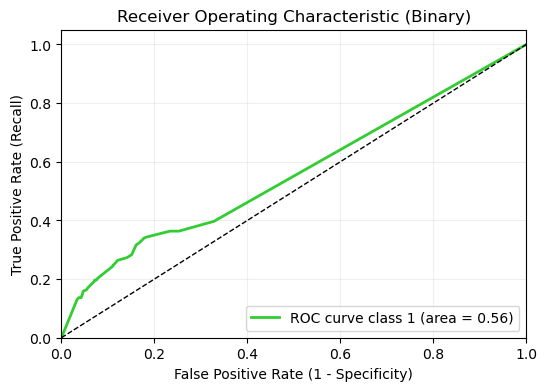

In [103]:
from sklearn.metrics import roc_curve, auc, RocCurveDisplay

y_score0 = clf.predict_proba(X_testp)[:, 1]
fpr0, tpr0, thresholds0 = roc_curve(y_testp, y_score0)
roc_auc0 = auc(fpr0, tpr0)

plt.figure(figsize=(6, 4))
plt.plot(fpr0, tpr0, color='limegreen', lw=2, 
         label=f'ROC curve class 1 (area = {roc_auc0:.2f})')

plt.plot([0, 1], [0, 1], color='black', lw=1, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Receiver Operating Characteristic (Binary)')
plt.legend(loc="lower right")
plt.grid(alpha=0.2)
plt.show()

In [104]:
# storing class 1 ROC curve for successive comparisons
def plot_ROC_comparison(fpr, tpr):
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr0, tpr0, color='darkorange', lw=3, label='$AUC_0$ = %.3f' % (roc_auc0))
    plt.plot(fpr, tpr, color='green', lw=3, label='$AUC_1$ = %.3f' % (roc_auc))
    
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=16)
    plt.ylabel('True Positive Rate', fontsize=16)
    plt.title('ROC curve', fontsize=16)
    plt.legend(loc="lower right", fontsize=14, frameon=False)
    plt.tick_params(axis='both', which='major', labelsize=16)
    plt.show()

def plot_pca(X_pca, y_train):
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_train, cmap=plt.cm.prism, edgecolor='k', alpha=0.7)
    plt.show()

In [105]:
from imblearn.under_sampling import RandomUnderSampler
from imblearn.under_sampling import CondensedNearestNeighbour
from imblearn.under_sampling import TomekLinks
from imblearn.under_sampling import EditedNearestNeighbours
from imblearn.over_sampling import RandomOverSampler
from imblearn.over_sampling import SMOTE
from imblearn.over_sampling import ADASYN

## Scelte finali

1. Undersampling: CondensedNearestNeighbour
2. Oversampling: SMOTE o ADASYN
3. Balancing at the Algorithm Level: Class Weight

Resampled dataset shape Counter({np.int64(0): 1382, np.int64(1): 700})


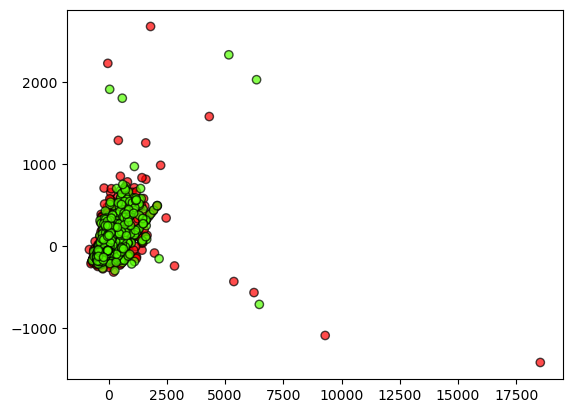

Migliori iperparametri CNN: {'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 20, 'criterion': 'entropy'}
Accuracy 0.7152693398136898
F1-score [0.82455703 0.24489796]
              precision    recall  f1-score   support

           0       0.90      0.76      0.82      2169
           1       0.18      0.38      0.24       300

    accuracy                           0.72      2469
   macro avg       0.54      0.57      0.53      2469
weighted avg       0.81      0.72      0.75      2469



In [106]:
# --- CondensedNearestNeighbour ---
cnn = CondensedNearestNeighbour(random_state=42, n_neighbors=1, n_jobs=-1)
X_res_cnn, y_res_cnn = cnn.fit_resample(X_trainp, y_trainp)
print('Resampled dataset shape %s' % Counter(y_res_cnn))
pca = PCA(n_components=2)
pca.fit(X_trainp)
X_pca = pca.transform(X_res_cnn)
plot_pca(X_pca, y_res_cnn)

# Tuning dedicato per CNN
rs_cnn = RandomizedSearchCV(DecisionTreeClassifier(random_state=222), param_distributions=param_dist, n_iter=20, scoring='f1', cv=5, random_state=222, n_jobs=-1)
rs_cnn.fit(X_res_cnn, y_res_cnn)
best_cnn = rs_cnn.best_estimator_
print('Migliori iperparametri CNN:', rs_cnn.best_params_)

# predict
y_pred = best_cnn.predict(X_testp)
print('Accuracy %s' % accuracy_score(y_testp, y_pred))
print('F1-score %s' % f1_score(y_testp, y_pred, average=None))
print(classification_report(y_testp, y_pred))


Resampled dataset shape Counter({np.int64(1): 5243, np.int64(0): 5060})


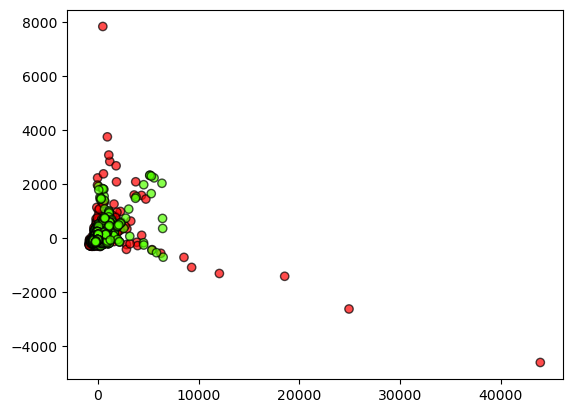

Migliori iperparametri ADASYN: {'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 20, 'criterion': 'entropy'}
Accuracy 0.7954637505062778
F1-score [0.88192658 0.23600605]
              precision    recall  f1-score   support

           0       0.89      0.87      0.88      2169
           1       0.22      0.26      0.24       300

    accuracy                           0.80      2469
   macro avg       0.56      0.56      0.56      2469
weighted avg       0.81      0.80      0.80      2469



In [107]:
# --- ADASYN ---
ada = ADASYN(random_state=42, n_neighbors=5)
X_res_ada, y_res_ada = ada.fit_resample(X_trainp, y_trainp)
print('Resampled dataset shape %s' % Counter(y_res_ada))
pca = PCA(n_components=2)
pca.fit(X_trainp)
X_pca = pca.transform(X_res_ada)
plot_pca(X_pca, y_res_ada)

# Tuning dedicato per ADASYN
rs_ada = RandomizedSearchCV(DecisionTreeClassifier(random_state=222), param_distributions=param_dist, n_iter=20, scoring='f1', cv=5, random_state=222, n_jobs=-1)
rs_ada.fit(X_res_ada, y_res_ada)
best_ada = rs_ada.best_estimator_
print('Migliori iperparametri ADASYN:', rs_ada.best_params_)

# predict
y_pred = best_ada.predict(X_testp)
print('Accuracy %s' % accuracy_score(y_testp, y_pred))
print('F1-score %s' % f1_score(y_testp, y_pred, average=None))
print(classification_report(y_testp, y_pred))


Resampled dataset shape Counter({np.int64(0): 5060, np.int64(1): 5060})


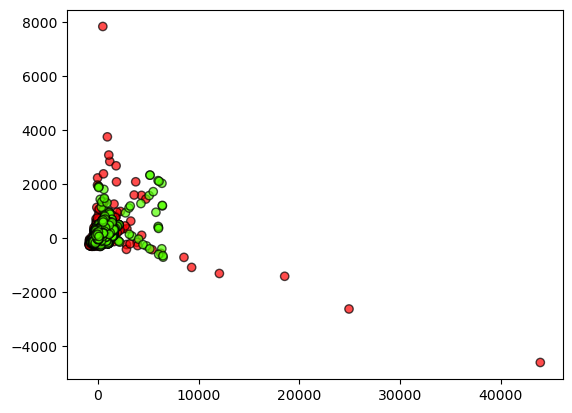

Migliori iperparametri SMOTE: {'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': 10, 'criterion': 'gini'}
Accuracy 0.8124746861077359
F1-score [0.89353874 0.2139219 ]
              precision    recall  f1-score   support

           0       0.89      0.90      0.89      2169
           1       0.22      0.21      0.21       300

    accuracy                           0.81      2469
   macro avg       0.55      0.55      0.55      2469
weighted avg       0.81      0.81      0.81      2469



In [108]:
# --- SMOTE ---
sm = SMOTE(random_state=42, k_neighbors=5)
X_res_sm, y_res_sm = sm.fit_resample(X_trainp, y_trainp)
print('Resampled dataset shape %s' % Counter(y_res_sm))
pca = PCA(n_components=2)
pca.fit(X_trainp)
X_pca = pca.transform(X_res_sm)
plot_pca(X_pca, y_res_sm)

# Tuning dedicato per SMOTE
rs_sm = RandomizedSearchCV(DecisionTreeClassifier(random_state=222), param_distributions=param_dist, n_iter=20, scoring='f1', cv=5, random_state=222, n_jobs=-1)
rs_sm.fit(X_res_sm, y_res_sm)
best_sm = rs_sm.best_estimator_
print('Migliori iperparametri SMOTE:', rs_sm.best_params_)

# predict
y_pred = best_sm.predict(X_testp)
print('Accuracy %s' % accuracy_score(y_testp, y_pred))
print('F1-score %s' % f1_score(y_testp, y_pred, average=None))
print(classification_report(y_testp, y_pred))


### Scelta Parametri: Class Weight (Algorithmic Balancing)
**Logica della scelta:**
Il bilanciamento tramite pesi agisce direttamente sulla funzione di costo del Decision Tree. È un metodo che non altera i dati originali (niente undersampling o oversampling) ed è spesso più robusto e veloce. 
Il parametro chiave nel `DecisionTreeClassifier` è `class_weight`. 
- `class_weight='balanced'` calcola i pesi in modo inversamente proporzionale alle frequenze (es. assegnerà un peso circa 100 volte superiore alla classe minoritaria).
- Proveremo anche dei pesi custom: `{0: 1, 1: 50}` e `{0: 1, 1: 150}` per penalizzare in modo asimmetrico i falsi negativi.

## Riassunto dei Risultati e Confronto Finale
In questa sezione alleniamo i modelli con i parametri ottimali emersi dal tuning e raccogliamo tutte le metriche, le curve ROC e le Matrici di Confusione in un'unica vista per facilitare il confronto.

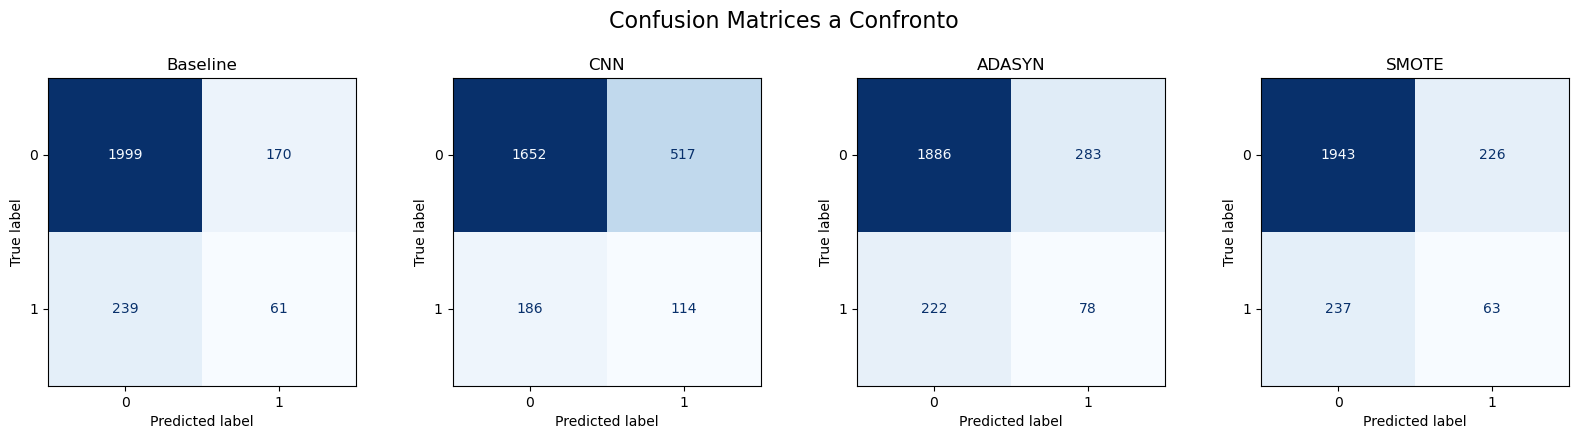

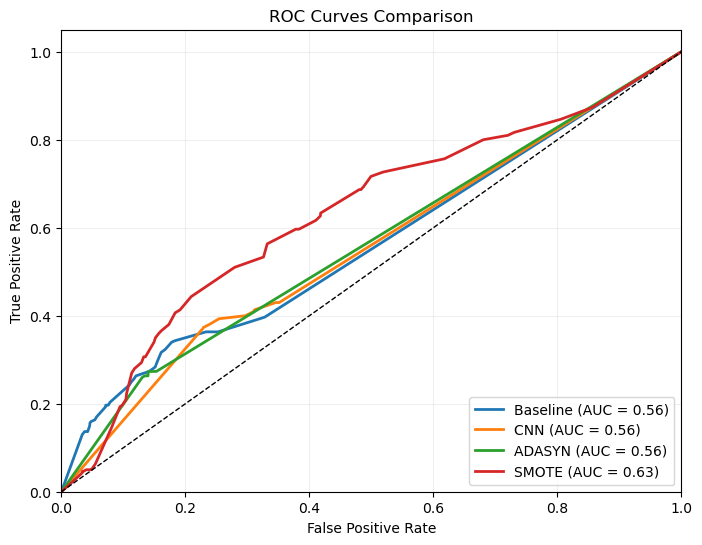

          Accuracy  Precision (Cl. 0)  Recall (Cl. 0)  F1-Score (Cl. 0)  Precision (Cl. 1)  Recall (Cl. 1)  F1-Score (Cl. 1)  ROC AUC
Baseline     0.834              0.893           0.922             0.907              0.264           0.203             0.230    0.561
CNN          0.715              0.899           0.762             0.825              0.181           0.380             0.245    0.556
ADASYN       0.795              0.895           0.870             0.882              0.216           0.260             0.236    0.562
SMOTE        0.812              0.891           0.896             0.894              0.218           0.210             0.214    0.629


Exception ignored in: <function ResourceTracker.__del__ at 0x103f7dc60>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 84, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 93, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 118, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x1029e9c60>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 84, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 93, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 118, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x103579c60>
Traceback (most recent call last

In [109]:
# Dizionario per salvare i risultati
results = {}
methods_eval = {
    'Baseline': (best_base, X_testp, y_testp),
    'CNN': (best_cnn, X_testp, y_testp),
    'ADASYN': (best_ada, X_testp, y_testp),
    'SMOTE': (best_sm, X_testp, y_testp)
}

fig_cm, axes = plt.subplots(1, 4, figsize=(20, 4))
fig_cm.suptitle('Confusion Matrices a Confronto', fontsize=16, y=1.05)

plt.figure(figsize=(8, 6))  # Per la curva ROC

for i, (name, (model, X_eval, y_eval)) in enumerate(methods_eval.items()):
    y_pred = model.predict(X_eval)
    y_score = model.predict_proba(X_eval)[:, 1]
    
    acc = accuracy_score(y_eval, y_pred)
    f1_min = f1_score(y_eval, y_pred, pos_label=1)
    f1_maj = f1_score(y_eval, y_pred, pos_label=0)
    prec_min = precision_score(y_eval, y_pred, pos_label=1, zero_division=0)
    rec_min = recall_score(y_eval, y_pred, pos_label=1, zero_division=0)
    prec_maj = precision_score(y_eval, y_pred, pos_label=0, zero_division=0)
    rec_maj = recall_score(y_eval, y_pred, pos_label=0, zero_division=0)
    
    fpr, tpr, _ = roc_curve(y_eval, y_score)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.2f})')
    
    cm = confusion_matrix(y_eval, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(ax=axes[i], cmap='Blues', colorbar=False)
    axes[i].set_title(name)
    
    results[name] = {
        'Accuracy': round(acc, 3),
        'Precision (Cl. 0)': round(prec_maj, 3),
        'Recall (Cl. 0)': round(rec_maj, 3),
        'F1-Score (Cl. 0)': round(f1_maj, 3),
        'Precision (Cl. 1)': round(prec_min, 3),
        'Recall (Cl. 1)': round(rec_min, 3),
        'F1-Score (Cl. 1)': round(f1_min, 3),
        'ROC AUC': round(roc_auc, 3)
    }

plt.plot([0, 1], [0, 1], color='black', lw=1, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves Comparison')
plt.legend(loc='lower right')
plt.grid(alpha=0.2)
plt.show()

df_results = pd.DataFrame(results).T
print(df_results.to_string())
